# EXP02-B — Robustezza degli ottimizzatori su più inizializzazioni

Questo notebook estende **EXP02** mantenendo invariati il protocollo e le impostazioni del notebook finale:

- dataset MNIST 4 vs 9 ridotto a 3 feature;
- split train/test e grading set identici;
- feature map baseline con `FEATURE_REPS = 2`;
- ansatz baseline con `ANSATZ_REPS = 4`;
- loss NLL;
- readout mediante parità dell'indice dello stato di base;
- ottimizzatori e relativi iperparametri identici a EXP02.

La sola variabile aggiuntiva è il **seed dell'inizializzazione dei pesi**. Per ciascun seed, tutti gli ottimizzatori partono dallo stesso initial point. Il confronto è quindi paired rispetto all'inizializzazione.

Seed utilizzati: `10599`, `10600`, `10601`.

Il seed `10599` viene riutilizzato dagli artefatti del notebook finale quando disponibile; in caso contrario viene eseguito nuovamente. I run completati vengono salvati singolarmente e non sono ripetuti nelle esecuzioni successive.


## 1. Setup tecnico

In [1]:
import json
import time
import warnings
from dataclasses import asdict, dataclass, field
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as onp
import pandas as pd
import requests
from scipy.optimize import minimize

import pennylane as qml
from pennylane import numpy as np

try:
    import plotly.express as px
    PLOTLY_AVAILABLE = True
except Exception:
    PLOTLY_AVAILABLE = False

warnings.filterwarnings("default")

## 2. Configurazione

`RUN_EXP02B = True` esegue esclusivamente i run mancanti di EXP02-B.  
`REUSE_ORIGINAL_SEED = True` riutilizza gli artefatti originali di EXP02 per il seed `10599`, se compatibili.


In [2]:
# ============================================================
# Modalità di esecuzione EXP02-B
# ============================================================

RUN_EXP02B = True
REUSE_ORIGINAL_SEED = True
ALLOW_DATASET_DOWNLOAD = True

# Cartelle coerenti con il notebook finale.
ARTIFACT_ROOT = Path("final_vqc_artifacts")
EXP02B_ROOT = ARTIFACT_ROOT / "EXP02B_OPTIMIZER_ROBUSTNESS"
FIGURE_ROOT = EXP02B_ROOT / "figures"
EXP02B_ROOT.mkdir(parents=True, exist_ok=True)
FIGURE_ROOT.mkdir(parents=True, exist_ok=True)

# ============================================================
# Costanti identiche al notebook finale
# ============================================================

GLOBAL_SEED = 10598
INIT_LOW = -0.05
INIT_HIGH = 0.05

N_QUBITS = 3
CORPUS_PERCENTAGE = 4
TEST_PERCENTAGE = 5
GRADING_DATASET_SIZE = 2000
GRADING_PER_CLASS = GRADING_DATASET_SIZE // 2
EPS = 1e-10
PRINT_EVERY = 10

DATASET_URL = "https://gitlab.com/GlazeDonuts/vqc-datasets/-/raw/master/datasets/dataset_4_9.csv"
DATASET_PATH = Path("dataset_4_9.csv")

# EXP02-B: stessi optimizer di EXP02, più inizializzazioni condivise.
EXP02B_OPTIMIZERS = ["COBYLA", "ADAM", "LBFGSB", "SPSA"]
EXP02B_INIT_SEEDS = [10599, 10600, 10601]
ORIGINAL_INIT_SEED = 10599

onp.random.seed(GLOBAL_SEED)
np.random.seed(GLOBAL_SEED)

print("RUN_EXP02B:", RUN_EXP02B)
print("REUSE_ORIGINAL_SEED:", REUSE_ORIGINAL_SEED)
print("EXP02-B root:", EXP02B_ROOT.resolve())
print("Initial seeds:", EXP02B_INIT_SEEDS)
print("Optimizers:", EXP02B_OPTIMIZERS)


RUN_EXP02B: True
REUSE_ORIGINAL_SEED: True
EXP02-B root: C:\Users\veron.PC-VERONICA\Desktop\Università\II anno\HPQC\progetto\MNIST\final_vqc_artifacts\EXP02B_OPTIMIZER_ROBUSTNESS
Initial seeds: [10599, 10600, 10601]
Optimizers: ['COBYLA', 'ADAM', 'LBFGSB', 'SPSA']


## 3. Dataset e controlli

In [3]:
def load_dataset(dataset_path=DATASET_PATH):
    dataset_path = Path(dataset_path)

    if not dataset_path.exists():
        if not ALLOW_DATASET_DOWNLOAD:
            raise FileNotFoundError(
                f"Dataset non trovato in {dataset_path}. "
                "Impostare ALLOW_DATASET_DOWNLOAD=True oppure copiare dataset_4_9.csv nella cartella del notebook."
            )
        response = requests.get(DATASET_URL, timeout=60)
        response.raise_for_status()
        dataset_path.write_bytes(response.content)

    raw = onp.loadtxt(dataset_path, delimiter=",")
    labels_original = raw[:, 0].astype(int)
    features = raw[:, 1:]
    labels_binary = onp.where(labels_original == 4, 0, 1).astype(int)
    return raw, features, labels_original, labels_binary


data, data_features, data_labels_original, data_labels = load_dataset(DATASET_PATH)

print("Dataset shape:", data.shape)
print("Feature shape:", data_features.shape)
print("Label originali:", onp.unique(data_labels_original))
print("Label binarie:", onp.unique(data_labels))

Dataset shape: (6000, 4)
Feature shape: (6000, 3)
Label originali: [4 9]
Label binarie: [0 1]


In [4]:
def validate_dataset(raw, features, labels_original, labels_binary):
    assert raw.shape == (6000, 4), f"Shape dataset inattesa: {raw.shape}"
    assert features.shape[1] == N_QUBITS, f"Numero feature inatteso: {features.shape[1]}"
    assert set(onp.unique(labels_original).tolist()) == {4, 9}, "Le label originali devono essere solo 4 e 9."
    assert set(onp.unique(labels_binary).tolist()) == {0, 1}, "Le label binarie devono essere solo 0 e 1."
    assert not onp.isnan(raw).any(), "Il dataset contiene NaN."

    # Controlli anti-leakage specifici per l'errore di lettura della label.
    assert not onp.array_equal(features[:, 0], labels_original), (
        "Possibile data leakage: la prima feature coincide con la label originale."
    )
    assert not set(onp.unique(features[:, 0]).tolist()).issubset({4, 9}), (
        "Possibile data leakage: la prima feature contiene solo valori 4/9."
    )

    return True

validate_dataset(data, data_features, data_labels_original, data_labels)
print("Controlli dataset superati.")

Controlli dataset superati.


## 4. Split train/test e grading set

In [5]:
def build_train_test_split(labels_original, labels_binary, features):
    corp_split = int(CORPUS_PERCENTAGE * features.shape[0] // 100)
    rng_split = onp.random.default_rng(GLOBAL_SEED)

    idx_digit_4_all = onp.where(labels_original == 4)[0]
    idx_digit_9_all = onp.where(labels_original == 9)[0]

    four_indices = rng_split.choice(idx_digit_4_all, corp_split // 2, replace=False)
    nine_indices = rng_split.choice(idx_digit_9_all, corp_split // 2, replace=False)

    semi_split = int(TEST_PERCENTAGE * corp_split // 200)

    train_idx_4 = four_indices[:-semi_split]
    test_idx_4 = four_indices[-semi_split:]
    train_idx_9 = nine_indices[:-semi_split]
    test_idx_9 = nine_indices[-semi_split:]

    train_indices = onp.concatenate([train_idx_4, train_idx_9])
    test_indices = onp.concatenate([test_idx_4, test_idx_9])
    train_test_indices = onp.concatenate([train_indices, test_indices])

    X_train = features[train_indices]
    y_train = labels_binary[train_indices]
    X_test = features[test_indices]
    y_test = labels_binary[test_indices]

    assert X_train.shape == (228, 3), f"Training set inatteso: {X_train.shape}"
    assert X_test.shape == (12, 3), f"Test set inatteso: {X_test.shape}"
    assert onp.intersect1d(train_indices, test_indices).size == 0, "Overlap tra train e test."
    assert pd.Series(y_train).value_counts().sort_index().to_dict() == {0: 114, 1: 114}
    assert pd.Series(y_test).value_counts().sort_index().to_dict() == {0: 6, 1: 6}

    return {
        "X_train": X_train,
        "y_train": y_train,
        "X_test": X_test,
        "y_test": y_test,
        "train_indices": train_indices,
        "test_indices": test_indices,
        "train_test_indices": train_test_indices,
    }

split = build_train_test_split(data_labels_original, data_labels, data_features)
X_train = split["X_train"]
y_train = split["y_train"]
X_test = split["X_test"]
y_test = split["y_test"]
train_indices = split["train_indices"]
test_indices = split["test_indices"]
train_test_indices = split["train_test_indices"]

print("X_train:", X_train.shape, "class counts:", pd.Series(y_train).value_counts().sort_index().to_dict())
print("X_test:", X_test.shape, "class counts:", pd.Series(y_test).value_counts().sort_index().to_dict())

X_train: (228, 3) class counts: {0: 114, 1: 114}
X_test: (12, 3) class counts: {0: 6, 1: 6}


In [6]:
def build_balanced_grading_set(labels_original, labels_binary, features, train_test_indices):
    idx_digit_4_all = onp.where(labels_original == 4)[0]
    idx_digit_9_all = onp.where(labels_original == 9)[0]

    available_digit_4 = onp.setdiff1d(idx_digit_4_all, train_test_indices)
    available_digit_9 = onp.setdiff1d(idx_digit_9_all, train_test_indices)

    assert available_digit_4.shape[0] >= GRADING_PER_CLASS
    assert available_digit_9.shape[0] >= GRADING_PER_CLASS

    grading_idx_4 = available_digit_4[-GRADING_PER_CLASS:]
    grading_idx_9 = available_digit_9[-GRADING_PER_CLASS:]

    grading_idx = onp.concatenate([grading_idx_4, grading_idx_9])
    rng_grading = onp.random.default_rng(GLOBAL_SEED)
    grading_idx = rng_grading.permutation(grading_idx)

    grading_features = features[grading_idx]
    grading_labels_original = labels_original[grading_idx]
    grading_labels = labels_binary[grading_idx]

    overlap = onp.intersect1d(train_test_indices, grading_idx).size
    counts = pd.Series(grading_labels).value_counts().sort_index()

    assert grading_features.shape == (GRADING_DATASET_SIZE, N_QUBITS)
    assert grading_labels.shape == (GRADING_DATASET_SIZE,)
    assert set(onp.unique(grading_labels_original).tolist()) == {4, 9}
    assert set(onp.unique(grading_labels).tolist()) == {0, 1}
    assert overlap == 0, "Overlap tra train/test e grading."
    assert int(counts.loc[0]) == GRADING_PER_CLASS
    assert int(counts.loc[1]) == GRADING_PER_CLASS

    return grading_features, grading_labels, grading_labels_original, grading_idx, counts, overlap

grading_features, grading_labels, grading_labels_original, grading_idx, grading_counts, overlap_train_test_grading = build_balanced_grading_set(
    data_labels_original,
    data_labels,
    data_features,
    train_test_indices,
)

print("Grading features:", grading_features.shape)
print("Grading labels:", grading_labels.shape)
print("Conteggio grading:", grading_counts.to_dict())
print("Overlap train/test-grading:", overlap_train_test_grading)

Grading features: (2000, 3)
Grading labels: (2000,)
Conteggio grading: {0: 1000, 1: 1000}
Overlap train/test-grading: 0


## 5. Configurazione circuitale e degli ottimizzatori

In [7]:
@dataclass
class ExperimentConfig:
    experiment_id: str
    experiment_type: str
    changed_factor: str
    feature_map_type: str
    feature_reps: int
    ansatz_type: str = "hardware_efficient_ry_rz_linear_cnot"
    ansatz_reps: int = 4
    optimizer: str = "COBYLA"
    loss: str = "nll"
    feature_entanglement_pairs: list = field(default_factory=lambda: [(2, 1), (1, 0)])
    ansatz_entanglement_pairs: list = field(default_factory=lambda: [(0, 1), (1, 2)])
    optimizer_config: dict = field(default_factory=dict)
    notes: str = ""

    @property
    def weights_shape(self):
        return (self.ansatz_reps + 1, N_QUBITS, 2)

    @property
    def n_weights(self):
        return int(onp.prod(self.weights_shape))


def default_optimizer_config(name):
    name = name.upper()
    if name == "COBYLA":
        return {"maxiter": 300, "tol": 1e-6}
    if name == "ADAM":
        return {"steps": 150, "stepsize": 0.05}
    if name == "LBFGSB":
        return {"maxiter": 300, "maxfun": 300, "ftol": 1e-9, "gtol": 1e-5}
    if name == "SPSA":
        return {"maxiter": 150, "a": 0.10, "c": 0.10, "alpha": 0.602, "gamma": 0.101, "seed": GLOBAL_SEED}
    raise ValueError(f"Optimizer non riconosciuto: {name}")


def cfg(
    experiment_id,
    experiment_type,
    changed_factor,
    feature_map_type="baseline_entangled",
    feature_reps=2,
    ansatz_reps=4,
    optimizer="COBYLA",
    loss="nll",
    feature_entanglement_pairs=None,
    notes="",
):
    if feature_entanglement_pairs is None:
        if feature_map_type == "full_pairwise_entangled":
            feature_entanglement_pairs = [(2, 1), (1, 0), (2, 0)]
        elif feature_map_type == "local_rx_rz":
            feature_entanglement_pairs = []
        else:
            feature_entanglement_pairs = [(2, 1), (1, 0)]

    return ExperimentConfig(
        experiment_id=experiment_id,
        experiment_type=experiment_type,
        changed_factor=changed_factor,
        feature_map_type=feature_map_type,
        feature_reps=feature_reps,
        ansatz_reps=ansatz_reps,
        optimizer=optimizer.upper(),
        loss=loss,
        feature_entanglement_pairs=list(feature_entanglement_pairs),
        optimizer_config=default_optimizer_config(optimizer),
        notes=notes,
    )

def make_exp02b_config(optimizer_name):
    """Configurazione baseline di EXP02 con il solo optimizer variabile."""
    return cfg(
        experiment_id=f"EXP02B_{optimizer_name}",
        experiment_type="robustness",
        changed_factor="optimizer+initialization_seed",
        feature_map_type="baseline_entangled",
        feature_reps=2,
        ansatz_reps=4,
        optimizer=optimizer_name,
        loss="nll",
        notes="EXP02-B: paired multi-seed optimizer robustness benchmark.",
    )

EXP02B_CONFIGS = {
    optimizer_name: make_exp02b_config(optimizer_name)
    for optimizer_name in EXP02B_OPTIMIZERS
}

pd.DataFrame([
    {
        "optimizer": name,
        "feature_map_type": cfg_obj.feature_map_type,
        "feature_reps": cfg_obj.feature_reps,
        "ansatz_reps": cfg_obj.ansatz_reps,
        "loss": cfg_obj.loss,
        "n_weights": cfg_obj.n_weights,
        "optimizer_config": cfg_obj.optimizer_config,
    }
    for name, cfg_obj in EXP02B_CONFIGS.items()
])


,optimizer,feature_map_type,feature_reps,ansatz_reps,loss,n_weights,optimizer_config
0,COBYLA,baseline_entangled,2,4,nll,30,"{'maxiter': 300, 'tol': 1e-06}"
1,ADAM,baseline_entangled,2,4,nll,30,"{'steps': 150, 'stepsize': 0.05}"
2,LBFGSB,baseline_entangled,2,4,nll,30,"{'maxiter': 300, 'maxfun': 300, 'ftol': 1e-09,..."
3,SPSA,baseline_entangled,2,4,nll,30,"{'maxiter': 150, 'a': 0.1, 'c': 0.1, 'alpha': ..."


## 6. Feature map, ansatz e inizializzazione parametrizzata

In [9]:
def feature_map(x, exp_cfg: ExperimentConfig):
    if exp_cfg.feature_map_type == "local_rx_rz":
        for _ in range(exp_cfg.feature_reps):
            for wire in range(N_QUBITS):
                qml.RX(x[wire], wires=wire)
                qml.RZ(x[wire], wires=wire)
        return

    if exp_cfg.feature_map_type in {"baseline_entangled", "full_pairwise_entangled"}:
        for _ in range(exp_cfg.feature_reps):
            for wire in range(N_QUBITS):
                qml.RX(x[wire], wires=wire)
                qml.RZ(x[wire], wires=wire)

            for control, target in exp_cfg.feature_entanglement_pairs:
                qml.RX(x[target], wires=target)
                qml.CNOT(wires=[control, target])
                qml.RX(x[target], wires=target)

            for wire in range(N_QUBITS):
                qml.RX(x[wire], wires=wire)
                qml.RZ(x[wire], wires=wire)
        return

    raise ValueError(f"feature_map_type non riconosciuto: {exp_cfg.feature_map_type}")


def ansatz(weights, exp_cfg: ExperimentConfig):
    for layer in range(exp_cfg.ansatz_reps):
        for wire in range(N_QUBITS):
            qml.RY(weights[layer, wire, 0], wires=wire)
            qml.RZ(weights[layer, wire, 1], wires=wire)

        for control, target in exp_cfg.ansatz_entanglement_pairs:
            qml.CNOT(wires=[control, target])

    final_layer = exp_cfg.ansatz_reps
    for wire in range(N_QUBITS):
        qml.RY(weights[final_layer, wire, 0], wires=wire)
        qml.RZ(weights[final_layer, wire, 1], wires=wire)


def make_qnode(exp_cfg: ExperimentConfig):
    dev = qml.device("default.qubit", wires=N_QUBITS)

    @qml.qnode(dev, interface="autograd")
    def circuit(x, weights):
        feature_map(x, exp_cfg)
        ansatz(weights, exp_cfg)
        return qml.probs(wires=[2, 1, 0])

    return circuit


def make_initial_weights(exp_cfg: ExperimentConfig, init_seed):
    rng_init = onp.random.default_rng(int(init_seed))
    initial_weights = rng_init.uniform(
        low=INIT_LOW,
        high=INIT_HIGH,
        size=exp_cfg.weights_shape,
    )
    return np.array(initial_weights, requires_grad=False)


def flatten_weights(weights):
    return onp.ravel(onp.asarray(weights, dtype=float))

def weights_from_flat(flat_params, exp_cfg: ExperimentConfig):
    """
    Ricostruisce il tensore dei pesi preservando la differenziabilità.

    Non usare onp.asarray(..., dtype=float) qui:
    Adam e L-BFGS-B tramite PennyLane/Autograd passano oggetti differenziabili
    che devono restare tracciabili.
    """
    return np.reshape(flat_params, exp_cfg.weights_shape)

## 7. Readout, loss e metriche

In [10]:
def aggregate_binary_probs(probs):
    prob_class_0 = np.sum(probs[0::2])
    prob_class_1 = np.sum(probs[1::2])
    return np.stack([prob_class_0, prob_class_1])


def class_probs_one(x_i, weights, circuit):
    return aggregate_binary_probs(circuit(x_i, weights))


def compute_loss(flat_params, X, y, exp_cfg: ExperimentConfig, circuit):
    weights = weights_from_flat(flat_params, exp_cfg)
    losses = []

    if exp_cfg.loss == "nll":
        for x_i, y_i in zip(X, y):
            probs = class_probs_one(x_i, weights, circuit)
            losses.append(-np.log(probs[int(y_i)] + EPS))
        return np.mean(np.stack(losses))

    if exp_cfg.loss == "mse":
        for x_i, y_i in zip(X, y):
            probs = class_probs_one(x_i, weights, circuit)
            losses.append((probs[1] - y_i) ** 2)
        return np.mean(np.stack(losses))

    raise ValueError(f"Loss non riconosciuta: {exp_cfg.loss}")


def compute_loss_value(flat_params, X, y, exp_cfg: ExperimentConfig, circuit):
    return float(compute_loss(flat_params, X, y, exp_cfg, circuit))

In [11]:
def compute_circuit_cost(exp_cfg: ExperimentConfig):
    if exp_cfg.feature_map_type == "local_rx_rz":
        feature_rotations_per_rep = 2 * N_QUBITS
        feature_cnots_per_rep = 0
    elif exp_cfg.feature_map_type in {"baseline_entangled", "full_pairwise_entangled"}:
        feature_rotations_per_rep = 2 * N_QUBITS + 2 * len(exp_cfg.feature_entanglement_pairs) + 2 * N_QUBITS
        feature_cnots_per_rep = len(exp_cfg.feature_entanglement_pairs)
    else:
        raise ValueError(f"feature_map_type non riconosciuto: {exp_cfg.feature_map_type}")

    feature_rotations = exp_cfg.feature_reps * feature_rotations_per_rep
    feature_cnots = exp_cfg.feature_reps * feature_cnots_per_rep

    ansatz_rotations = (exp_cfg.ansatz_reps + 1) * N_QUBITS * 2
    ansatz_cnots = exp_cfg.ansatz_reps * len(exp_cfg.ansatz_entanglement_pairs)

    single_qubit_rotations = feature_rotations + ansatz_rotations
    cnots = feature_cnots + ansatz_cnots
    circuit_cost = single_qubit_rotations + 10 * cnots

    return {
        "feature_rotations": int(feature_rotations),
        "feature_cnots": int(feature_cnots),
        "ansatz_rotations": int(ansatz_rotations),
        "ansatz_cnots": int(ansatz_cnots),
        "single_qubit_rotations": int(single_qubit_rotations),
        "cnots": int(cnots),
        "circuit_cost": int(circuit_cost),
    }

cost_df = pd.DataFrame([
    {
        "optimizer": optimizer_name,
        "experiment_id": exp_cfg.experiment_id,
        **compute_circuit_cost(exp_cfg),
    }
    for optimizer_name, exp_cfg in EXP02B_CONFIGS.items()
])

cost_df[
    [
        "optimizer",
        "experiment_id",
        "single_qubit_rotations",
        "cnots",
        "circuit_cost",
    ]
]

,optimizer,experiment_id,single_qubit_rotations,cnots,circuit_cost
0,COBYLA,EXP02B_COBYLA,62,12,182
1,ADAM,EXP02B_ADAM,62,12,182
2,LBFGSB,EXP02B_LBFGSB,62,12,182
3,SPSA,EXP02B_SPSA,62,12,182


In [12]:
def predict_proba_dataset(X, flat_params, exp_cfg: ExperimentConfig, circuit):
    weights = weights_from_flat(flat_params, exp_cfg)
    probs = []
    for x_i in X:
        probs.append(onp.asarray(class_probs_one(x_i, weights, circuit), dtype=float))
    return onp.vstack(probs)


def evaluate_dataset(X, y, flat_params, exp_cfg: ExperimentConfig, circuit):
    probs = predict_proba_dataset(X, flat_params, exp_cfg, circuit)
    y_pred = onp.argmax(probs, axis=1).astype(int)
    accuracy = float(onp.mean(y_pred == y))
    return {
        "accuracy": accuracy,
        "y_pred": y_pred,
        "y_score": probs[:, 1],
        "probs": probs,
    }


def confusion_matrix_binary(y_true, y_pred):
    cm = onp.zeros((2, 2), dtype=int)
    for yt, yp in zip(y_true, y_pred):
        cm[int(yt), int(yp)] += 1
    return cm


def roc_curve_binary(y_true, y_score):
    y_true = onp.asarray(y_true).astype(int)
    y_score = onp.asarray(y_score, dtype=float)
    thresholds = onp.r_[onp.inf, onp.sort(onp.unique(y_score))[::-1], -onp.inf]

    fpr = []
    tpr = []
    for threshold in thresholds:
        y_pred = (y_score >= threshold).astype(int)
        tp = onp.sum((y_pred == 1) & (y_true == 1))
        fp = onp.sum((y_pred == 1) & (y_true == 0))
        tn = onp.sum((y_pred == 0) & (y_true == 0))
        fn = onp.sum((y_pred == 0) & (y_true == 1))
        fpr.append(fp / (fp + tn) if (fp + tn) > 0 else 0.0)
        tpr.append(tp / (tp + fn) if (tp + fn) > 0 else 0.0)

    fpr = onp.asarray(fpr, dtype=float)
    tpr = onp.asarray(tpr, dtype=float)
    order = onp.argsort(fpr)
    auc = float(onp.trapezoid(tpr[order], fpr[order]))
    return fpr, tpr, thresholds, auc


def save_confusion_matrix_plot(cm, title, output_path):
    output_path = Path(output_path)
    fig, ax = plt.subplots(figsize=(5, 5))
    im = ax.imshow(cm)
    ax.set_xticks([0, 1])
    ax.set_yticks([0, 1])
    ax.set_xticklabels(["pred 0 / digit 4", "pred 1 / digit 9"], rotation=20, ha="right")
    ax.set_yticklabels(["true 0 / digit 4", "true 1 / digit 9"])
    ax.set_title(title)
    for i in range(2):
        for j in range(2):
            ax.text(j, i, str(cm[i, j]), ha="center", va="center")
    fig.colorbar(im, ax=ax)
    plt.tight_layout()
    fig.savefig(output_path, dpi=150)
    plt.show()


def save_roc_plot(fpr, tpr, auc, title, output_path):
    output_path = Path(output_path)
    plt.figure(figsize=(6, 5))
    plt.plot(fpr, tpr, label=f"AUC = {auc:.4f}")
    plt.plot([0, 1], [0, 1], linestyle="--", label="random")
    plt.xlabel("False positive rate")
    plt.ylabel("True positive rate")
    plt.title(title)
    plt.grid(True)
    plt.legend()
    plt.tight_layout()
    plt.savefig(output_path, dpi=150)
    plt.show()

## 8. Implementazione degli ottimizzatori

In [13]:
def run_cobyla(initial_flat_params, exp_cfg, circuit):
    loss_history = []
    cfg_opt = exp_cfg.optimizer_config

    def objective(theta_np):
        value = compute_loss_value(theta_np, X_train, y_train, exp_cfg, circuit)
        loss_history.append(value)
        if len(loss_history) == 1 or len(loss_history) % PRINT_EVERY == 0:
            print(f"COBYLA valutazione {len(loss_history):03d} | loss = {value:.6f}")
        return value

    start = time.perf_counter()
    result = minimize(
        objective,
        x0=onp.asarray(initial_flat_params, dtype=float),
        method="COBYLA",
        tol=cfg_opt["tol"],
        options={"maxiter": cfg_opt["maxiter"], "disp": False},
    )
    training_time = time.perf_counter() - start

    return {
        "flat_params": onp.asarray(result.x, dtype=float),
        "loss_history": loss_history,
        "training_time_seconds": training_time,
        "optimizer_success": bool(result.success),
        "optimizer_message": str(result.message),
        "objective_evaluations": int(len(loss_history)),
        "optimizer_details": dict(cfg_opt),
    }


def run_adam(initial_flat_params, exp_cfg, circuit):
    cfg_opt = exp_cfg.optimizer_config
    optimizer = qml.AdamOptimizer(stepsize=cfg_opt["stepsize"])
    theta = np.array(initial_flat_params, requires_grad=True)
    loss_history = []

    def cost_fn(params):
        return compute_loss(params, X_train, y_train, exp_cfg, circuit)

    start = time.perf_counter()
    for step in range(1, cfg_opt["steps"] + 1):
        theta, loss_before_step = optimizer.step_and_cost(cost_fn, theta)
        loss_history.append(float(loss_before_step))
        if step == 1 or step % PRINT_EVERY == 0:
            print(f"Adam step {step:03d}/{cfg_opt['steps']} | loss = {float(loss_before_step):.6f}")

    final_loss = compute_loss_value(theta, X_train, y_train, exp_cfg, circuit)
    loss_history.append(final_loss)
    training_time = time.perf_counter() - start

    return {
        "flat_params": onp.asarray(theta, dtype=float),
        "loss_history": loss_history,
        "training_time_seconds": training_time,
        "optimizer_success": True,
        "optimizer_message": "Adam completed the configured number of steps.",
        "objective_evaluations": int(cfg_opt["steps"] + 1),
        "optimizer_details": dict(cfg_opt),
    }


def run_lbfgsb(initial_flat_params, exp_cfg, circuit):
    cfg_opt = exp_cfg.optimizer_config
    loss_history = []

    def objective(theta_np):
        value = compute_loss_value(theta_np, X_train, y_train, exp_cfg, circuit)
        loss_history.append(value)
        if len(loss_history) == 1 or len(loss_history) % PRINT_EVERY == 0:
            print(f"L-BFGS-B valutazione {len(loss_history):03d} | loss = {value:.6f}")
        return value

    def gradient(theta_np):
        theta = np.array(theta_np, requires_grad=True)

        def differentiable_objective(params):
            return compute_loss(params, X_train, y_train, exp_cfg, circuit)

        grad = qml.grad(differentiable_objective)(theta)
        return onp.asarray(grad, dtype=float)

    start = time.perf_counter()
    result = minimize(
        objective,
        x0=onp.asarray(initial_flat_params, dtype=float),
        method="L-BFGS-B",
        jac=gradient,
        options={
            "maxiter": cfg_opt["maxiter"],
            "maxfun": cfg_opt["maxfun"],
            "ftol": cfg_opt["ftol"],
            "gtol": cfg_opt["gtol"],
        },
    )
    training_time = time.perf_counter() - start

    return {
        "flat_params": onp.asarray(result.x, dtype=float),
        "loss_history": loss_history,
        "training_time_seconds": training_time,
        "optimizer_success": bool(result.success),
        "optimizer_message": str(result.message),
        "objective_evaluations": int(getattr(result, "nfev", len(loss_history))),
        "optimizer_details": {
            **dict(cfg_opt),
            "nfev": int(getattr(result, "nfev", len(loss_history))),
            "njev": int(getattr(result, "njev", -1)) if hasattr(result, "njev") else None,
            "nit": int(getattr(result, "nit", -1)) if hasattr(result, "nit") else None,
        },
    }


def run_spsa(initial_flat_params, exp_cfg, circuit):
    cfg_opt = exp_cfg.optimizer_config
    rng = onp.random.default_rng(cfg_opt["seed"])
    theta = onp.asarray(initial_flat_params, dtype=float).copy()
    loss_history = []

    start = time.perf_counter()
    for iteration in range(1, cfg_opt["maxiter"] + 1):
        ak = cfg_opt["a"] / (iteration ** cfg_opt["alpha"])
        ck = cfg_opt["c"] / (iteration ** cfg_opt["gamma"])
        delta = rng.choice([-1.0, 1.0], size=theta.shape)

        loss_plus = compute_loss_value(theta + ck * delta, X_train, y_train, exp_cfg, circuit)
        loss_minus = compute_loss_value(theta - ck * delta, X_train, y_train, exp_cfg, circuit)
        grad_estimate = ((loss_plus - loss_minus) / (2.0 * ck)) * delta
        theta = theta - ak * grad_estimate

        current_loss = compute_loss_value(theta, X_train, y_train, exp_cfg, circuit)
        loss_history.append(current_loss)

        if iteration == 1 or iteration % PRINT_EVERY == 0:
            print(f"SPSA iterazione {iteration:03d}/{cfg_opt['maxiter']} | loss = {current_loss:.6f}")

    training_time = time.perf_counter() - start

    return {
        "flat_params": onp.asarray(theta, dtype=float),
        "loss_history": loss_history,
        "training_time_seconds": training_time,
        "optimizer_success": True,
        "optimizer_message": "SPSA completed the configured number of iterations.",
        "objective_evaluations": int(3 * cfg_opt["maxiter"]),
        "optimizer_details": dict(cfg_opt),
    }


OPTIMIZER_RUNNERS = {
    "COBYLA": run_cobyla,
    "ADAM": run_adam,
    "LBFGSB": run_lbfgsb,
    "SPSA": run_spsa,
}

## 9. Artefatti e riuso del seed originale

In [14]:
ORIGINAL_ARTIFACT_IDS = {
    "COBYLA": "BASELINE00_PENNYLANE",
    "ADAM": "EXP02_ADAM",
    "LBFGSB": "EXP02_LBFGSB",
    "SPSA": "EXP02_SPSA",
}


def initialization_name(init_seed):
    return f"uniform[{INIT_LOW},{INIT_HIGH}]_seed{int(init_seed)}"


def exp02b_run_dir(optimizer_name, init_seed):
    path = EXP02B_ROOT / f"{optimizer_name}_seed{int(init_seed)}"
    path.mkdir(parents=True, exist_ok=True)
    return path


def exp02b_run_paths(optimizer_name, init_seed):
    d = exp02b_run_dir(optimizer_name, init_seed)
    return {
        "dir": d,
        "results": d / "results.json",
        "trained_flat_weights": d / "trained_flat_weights.npy",
        "loss_history": d / "loss_history.npy",
    }


def load_exp02b_run(optimizer_name, init_seed):
    paths = exp02b_run_paths(optimizer_name, init_seed)
    if not paths["results"].exists():
        return None
    with open(paths["results"], "r", encoding="utf-8") as f:
        result = json.load(f)
    compatible = (
        result.get("optimizer") == optimizer_name
        and int(result.get("init_seed", -1)) == int(init_seed)
        and result.get("initialization_name") == initialization_name(init_seed)
        and result.get("feature_map_type") == "baseline_entangled"
        and int(result.get("feature_reps", -1)) == 2
        and int(result.get("ansatz_reps", -1)) == 4
        and result.get("loss") == "nll"
    )
    return result if compatible else None


def load_original_seed_result(optimizer_name):
    """Legge il risultato originale di EXP02 dal notebook finale."""
    artifact_id = ORIGINAL_ARTIFACT_IDS[optimizer_name]
    result_path = ARTIFACT_ROOT / artifact_id / "results.json"
    if not result_path.exists():
        return None

    with open(result_path, "r", encoding="utf-8") as f:
        original = json.load(f)

    compatible = (
        int(original.get("init_seed", -1)) == ORIGINAL_INIT_SEED
        and original.get("initialization_name") == initialization_name(ORIGINAL_INIT_SEED)
        and original.get("feature_map_type") == "baseline_entangled"
        and int(original.get("feature_reps", -1)) == 2
        and int(original.get("ansatz_reps", -1)) == 4
        and original.get("loss") == "nll"
        and original.get("optimizer") == optimizer_name
    )
    if not compatible:
        return None

    return {
        **original,
        "experiment_id": f"EXP02B_{optimizer_name}_SEED{ORIGINAL_INIT_SEED}",
        "experiment_type": "robustness",
        "changed_factor": "optimizer+initialization_seed",
        "source": "reused_from_original_EXP02",
    }


def save_exp02b_run(result, flat_weights=None, loss_history=None):
    optimizer_name = result["optimizer"]
    init_seed = int(result["init_seed"])
    paths = exp02b_run_paths(optimizer_name, init_seed)

    with open(paths["results"], "w", encoding="utf-8") as f:
        json.dump(result, f, indent=2, ensure_ascii=False)

    if flat_weights is not None:
        onp.save(paths["trained_flat_weights"], onp.asarray(flat_weights, dtype=float))
    if loss_history is not None:
        onp.save(paths["loss_history"], onp.asarray(loss_history, dtype=float))

    return paths


## 10. Esecuzione di EXP02-B

La cella:

1. carica i run EXP02-B già completati;
2. riutilizza il seed `10599` dal notebook finale quando possibile;
3. esegue soltanto i run mancanti;
4. salva ogni risultato immediatamente.

Il notebook può quindi essere interrotto e ripreso senza perdere i run completati.


In [15]:
def run_exp02b_one(optimizer_name, init_seed):
    exp_cfg = EXP02B_CONFIGS[optimizer_name]
    circuit = make_qnode(exp_cfg)

    initial_weights = make_initial_weights(exp_cfg, init_seed)
    initial_point = flatten_weights(initial_weights)

    print("=" * 90)
    print(f"EXP02-B | optimizer={optimizer_name} | init_seed={init_seed}")
    print("=" * 90)

    train_output = OPTIMIZER_RUNNERS[optimizer_name](
        initial_point,
        exp_cfg,
        circuit,
    )

    trained_flat_weights = onp.asarray(train_output["flat_params"], dtype=float)
    loss_history = onp.asarray(train_output["loss_history"], dtype=float)

    final_loss = compute_loss_value(
        trained_flat_weights,
        X_train,
        y_train,
        exp_cfg,
        circuit,
    )

    train_eval = evaluate_dataset(
        X_train, y_train, trained_flat_weights, exp_cfg, circuit
    )
    test_eval = evaluate_dataset(
        X_test, y_test, trained_flat_weights, exp_cfg, circuit
    )

    grading_start = time.perf_counter()
    grading_eval = evaluate_dataset(
        grading_features,
        grading_labels,
        trained_flat_weights,
        exp_cfg,
        circuit,
    )
    grading_time = time.perf_counter() - grading_start

    _, _, _, roc_auc = roc_curve_binary(
        grading_labels,
        grading_eval["y_score"],
    )

    result = {
        "experiment_id": f"EXP02B_{optimizer_name}_SEED{int(init_seed)}",
        "experiment_type": "robustness",
        "changed_factor": "optimizer+initialization_seed",
        "source": "trained_in_EXP02B",
        "optimizer": optimizer_name,
        "loss": exp_cfg.loss,
        "feature_map_type": exp_cfg.feature_map_type,
        "feature_reps": int(exp_cfg.feature_reps),
        "ansatz_type": exp_cfg.ansatz_type,
        "ansatz_reps": int(exp_cfg.ansatz_reps),
        "global_seed": int(GLOBAL_SEED),
        "init_seed": int(init_seed),
        "init_low": float(INIT_LOW),
        "init_high": float(INIT_HIGH),
        "initialization_name": initialization_name(init_seed),
        "initial_point_norm": float(onp.linalg.norm(initial_point)),
        "n_qubits": int(N_QUBITS),
        "n_weights": int(exp_cfg.n_weights),
        "weights_shape": list(exp_cfg.weights_shape),
        "train_size": int(X_train.shape[0]),
        "test_size": int(X_test.shape[0]),
        "grading_size": int(grading_features.shape[0]),
        "grading_set_type": "balanced_1000_per_class_no_train_test_overlap",
        "train_accuracy": float(train_eval["accuracy"]),
        "test_accuracy": float(test_eval["accuracy"]),
        "grading_accuracy": float(grading_eval["accuracy"]),
        "roc_auc_grading": float(roc_auc),
        "final_loss": float(final_loss),
        "training_time_seconds": float(train_output["training_time_seconds"]),
        "grading_time_seconds": float(grading_time),
        "objective_evaluations": int(train_output["objective_evaluations"]),
        "optimizer_success": bool(train_output["optimizer_success"]),
        "optimizer_message": str(train_output["optimizer_message"]),
        "optimizer_details": train_output["optimizer_details"],
        **compute_circuit_cost(exp_cfg),
    }

    save_exp02b_run(
        result,
        flat_weights=trained_flat_weights,
        loss_history=loss_history,
    )
    return result


exp02b_results = []

for init_seed in EXP02B_INIT_SEEDS:
    for optimizer_name in EXP02B_OPTIMIZERS:
        existing = load_exp02b_run(optimizer_name, init_seed)
        if existing is not None:
            print(f"[caricato] {optimizer_name}, seed {init_seed}")
            exp02b_results.append(existing)
            continue

        if (
            REUSE_ORIGINAL_SEED
            and int(init_seed) == ORIGINAL_INIT_SEED
        ):
            reused = load_original_seed_result(optimizer_name)
            if reused is not None:
                save_exp02b_run(reused)
                print(f"[riutilizzato da EXP02] {optimizer_name}, seed {init_seed}")
                exp02b_results.append(reused)
                continue

        if RUN_EXP02B:
            result = run_exp02b_one(optimizer_name, init_seed)
            exp02b_results.append(result)
        else:
            print(f"[mancante] {optimizer_name}, seed {init_seed}")

runs_df = pd.DataFrame(exp02b_results)
runs_path = EXP02B_ROOT / "exp02b_all_runs.csv"
runs_df.to_csv(runs_path, index=False)

print("\nRun disponibili:", len(runs_df), "/", len(EXP02B_OPTIMIZERS) * len(EXP02B_INIT_SEEDS))
print("Tabella run:", runs_path.resolve())

if not runs_df.empty:
    display_columns = [
        "optimizer",
        "init_seed",
        "source",
        "train_accuracy",
        "test_accuracy",
        "grading_accuracy",
        "roc_auc_grading",
        "final_loss",
        "training_time_seconds",
        "objective_evaluations",
    ]
    display(runs_df[display_columns].sort_values(["init_seed", "optimizer"]).reset_index(drop=True))


[riutilizzato da EXP02] COBYLA, seed 10599
[riutilizzato da EXP02] ADAM, seed 10599
[riutilizzato da EXP02] LBFGSB, seed 10599
[riutilizzato da EXP02] SPSA, seed 10599
EXP02-B | optimizer=COBYLA | init_seed=10600
COBYLA valutazione 001 | loss = 0.652010
COBYLA valutazione 010 | loss = 0.648860
COBYLA valutazione 020 | loss = 0.651827
COBYLA valutazione 030 | loss = 0.646540
COBYLA valutazione 040 | loss = 0.614232
COBYLA valutazione 050 | loss = 0.634855
COBYLA valutazione 060 | loss = 0.592092
COBYLA valutazione 070 | loss = 0.708150
COBYLA valutazione 080 | loss = 0.660967
COBYLA valutazione 090 | loss = 0.566615
COBYLA valutazione 100 | loss = 0.538799
COBYLA valutazione 110 | loss = 0.536962
COBYLA valutazione 120 | loss = 0.535839
COBYLA valutazione 130 | loss = 0.532028
COBYLA valutazione 140 | loss = 0.527542
COBYLA valutazione 150 | loss = 0.524193
COBYLA valutazione 160 | loss = 0.524854
COBYLA valutazione 170 | loss = 0.522440
COBYLA valutazione 180 | loss = 0.522299
COBYLA v

,optimizer,init_seed,source,train_accuracy,test_accuracy,grading_accuracy,roc_auc_grading,final_loss,training_time_seconds,objective_evaluations
0,ADAM,10599,reused_from_original_EXP02,0.815789,0.833333,0.7875,0.813275,0.509112,594.452903,151
1,COBYLA,10599,reused_from_original_EXP02,0.811404,0.750000,0.7880,0.806068,0.519006,415.385782,300
2,LBFGSB,10599,reused_from_original_EXP02,0.820175,0.833333,0.7910,0.811980,0.509091,1604.579341,301
3,SPSA,10599,reused_from_original_EXP02,0.627193,0.750000,0.6160,0.713290,0.644991,629.107112,450
4,ADAM,10600,trained_in_EXP02B,0.820175,0.833333,0.7865,0.812930,0.509232,1233.360982,151
5,COBYLA,10600,trained_in_EXP02B,0.828947,0.833333,0.7865,0.807265,0.518852,975.571504,300
6,LBFGSB,10600,trained_in_EXP02B,0.820175,0.833333,0.7855,0.813043,0.509186,2890.434102,301
7,SPSA,10600,trained_in_EXP02B,0.644737,0.833333,0.6105,0.716219,0.644636,624.724884,450
8,ADAM,10601,trained_in_EXP02B,0.820175,0.833333,0.7875,0.813546,0.511463,578.120962,151
9,COBYLA,10601,trained_in_EXP02B,0.828947,0.833333,0.7820,0.806151,0.516368,414.539365,300


## 11. Statistiche aggregate e confronto paired

La media e la deviazione standard descrivono la variabilità rispetto all'inizializzazione.  
Il conteggio delle vittorie indica quante volte un ottimizzatore ha ottenuto la grading accuracy più alta sullo stesso seed.


In [16]:
EXPECTED_RUNS = len(EXP02B_OPTIMIZERS) * len(EXP02B_INIT_SEEDS)

if runs_df.empty:
    print("Nessun run disponibile.")
else:
    numeric_columns = [
        "grading_accuracy",
        "roc_auc_grading",
        "final_loss",
        "training_time_seconds",
        "objective_evaluations",
    ]
    for col in numeric_columns:
        runs_df[col] = pd.to_numeric(runs_df[col], errors="coerce")

    summary_df = (
        runs_df.groupby("optimizer", as_index=False)
        .agg(
            completed_runs=("init_seed", "count"),
            grading_accuracy_mean=("grading_accuracy", "mean"),
            grading_accuracy_std=("grading_accuracy", "std"),
            grading_accuracy_min=("grading_accuracy", "min"),
            grading_accuracy_max=("grading_accuracy", "max"),
            roc_auc_mean=("roc_auc_grading", "mean"),
            final_loss_mean=("final_loss", "mean"),
            training_time_mean_seconds=("training_time_seconds", "mean"),
            objective_evaluations_mean=("objective_evaluations", "mean"),
        )
    )

    # Vittorie paired per seed. In caso di parità, tutti i migliori ricevono una vittoria.
    wins = {name: 0 for name in EXP02B_OPTIMIZERS}
    for init_seed, seed_df in runs_df.groupby("init_seed"):
        if seed_df.empty:
            continue
        best_accuracy = seed_df["grading_accuracy"].max()
        winners = seed_df.loc[
            onp.isclose(seed_df["grading_accuracy"], best_accuracy),
            "optimizer",
        ].tolist()
        for winner in winners:
            wins[winner] += 1

    summary_df["wins_across_seeds"] = summary_df["optimizer"].map(wins).fillna(0).astype(int)
    summary_df = summary_df.sort_values(
        ["grading_accuracy_mean", "grading_accuracy_std"],
        ascending=[False, True],
    ).reset_index(drop=True)

    summary_path = EXP02B_ROOT / "exp02b_optimizer_summary.csv"
    summary_df.to_csv(summary_path, index=False)

    print("Run attesi:", EXPECTED_RUNS)
    print("Run completati:", len(runs_df))
    print("Riepilogo:", summary_path.resolve())
    display(summary_df)


Run attesi: 12
Run completati: 12
Riepilogo: C:\Users\veron.PC-VERONICA\Desktop\Università\II anno\HPQC\progetto\MNIST\final_vqc_artifacts\EXP02B_OPTIMIZER_ROBUSTNESS\exp02b_optimizer_summary.csv


,optimizer,completed_runs,grading_accuracy_mean,grading_accuracy_std,grading_accuracy_min,grading_accuracy_max,roc_auc_mean,final_loss_mean,training_time_mean_seconds,objective_evaluations_mean,wins_across_seeds
0,ADAM,3,0.787167,0.000577,0.7865,0.7875,0.813250,0.509935,801.978282,151.0,2
1,LBFGSB,3,0.786667,0.003884,0.7835,0.7910,0.811817,0.509108,2021.100286,301.0,1
2,COBYLA,3,0.785500,0.003122,0.7820,0.7880,0.806495,0.518075,601.832217,300.0,1
3,SPSA,3,0.612667,0.002930,0.6105,0.6160,0.713301,0.644637,624.452811,450.0,0


## 11A. Tabella comparativa per seed

La tabella seguente confronta direttamente, per ciascun seed di inizializzazione, la grading accuracy ottenuta dai quattro ottimizzatori. Ogni riga corrisponde a un initial point condiviso; le colonne corrispondono agli ottimizzatori.

Vengono inoltre riportati l'ottimizzatore migliore per ciascun seed, la migliore grading accuracy del seed e lo scarto di ciascun ottimizzatore rispetto al migliore sullo stesso seed. Questa vista è il confronto paired più diretto, perché separa l'effetto dell'inizializzazione da quello dell'ottimizzatore.


In [17]:
if runs_df.empty:
    print("Nessun run disponibile per costruire la tabella comparativa per seed.")
else:
    accuracy_by_seed = (
        runs_df.pivot_table(
            index="init_seed",
            columns="optimizer",
            values="grading_accuracy",
            aggfunc="first",
        )
        .reindex(columns=EXP02B_OPTIMIZERS)
        .sort_index()
    )

    accuracy_by_seed["best_optimizer"] = accuracy_by_seed[
        EXP02B_OPTIMIZERS
    ].idxmax(axis=1)
    accuracy_by_seed["best_grading_accuracy"] = accuracy_by_seed[
        EXP02B_OPTIMIZERS
    ].max(axis=1)

    for optimizer_name in EXP02B_OPTIMIZERS:
        accuracy_by_seed[f"delta_{optimizer_name}_vs_best"] = (
            accuracy_by_seed[optimizer_name]
            - accuracy_by_seed["best_grading_accuracy"]
        )

    accuracy_by_seed = accuracy_by_seed.reset_index()

    per_seed_path = EXP02B_ROOT / "exp02b_accuracy_comparison_by_seed.csv"
    accuracy_by_seed.to_csv(per_seed_path, index=False)

    print("Confronto per seed:", per_seed_path.resolve())
    display(accuracy_by_seed)


Confronto per seed: C:\Users\veron.PC-VERONICA\Desktop\Università\II anno\HPQC\progetto\MNIST\final_vqc_artifacts\EXP02B_OPTIMIZER_ROBUSTNESS\exp02b_accuracy_comparison_by_seed.csv


optimizer,init_seed,COBYLA,ADAM,LBFGSB,SPSA,best_optimizer,best_grading_accuracy,delta_COBYLA_vs_best,delta_ADAM_vs_best,delta_LBFGSB_vs_best,delta_SPSA_vs_best
0,10599,0.7880,0.7875,0.7910,0.6160,LBFGSB,0.7910,-0.0030,-0.0035,0.000,-0.175
1,10600,0.7865,0.7865,0.7855,0.6105,COBYLA,0.7865,0.0000,0.0000,-0.001,-0.176
2,10601,0.7820,0.7875,0.7835,0.6115,ADAM,0.7875,-0.0055,0.0000,-0.004,-0.176


## 12. Grafici

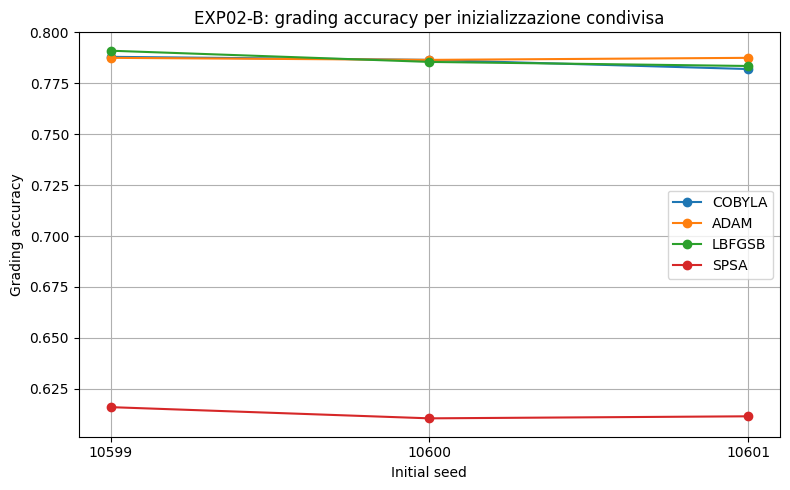

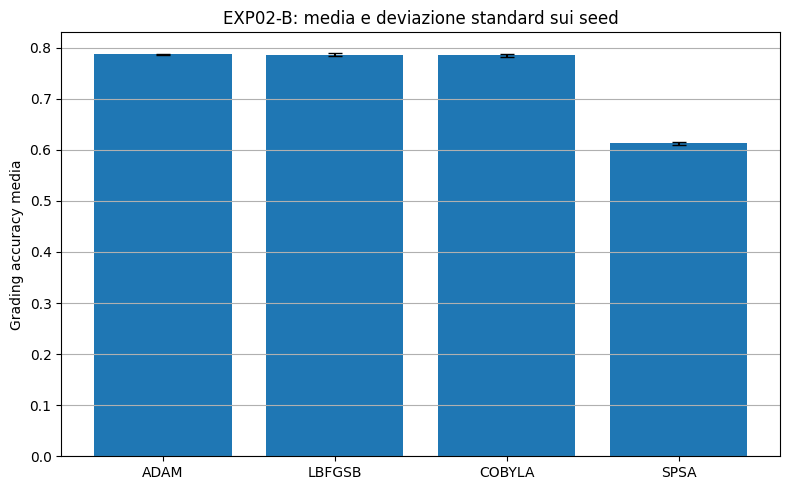

Grafici salvati in: C:\Users\veron.PC-VERONICA\Desktop\Università\II anno\HPQC\progetto\MNIST\final_vqc_artifacts\EXP02B_OPTIMIZER_ROBUSTNESS\figures


In [18]:
if not runs_df.empty:
    # Grafico paired: una linea per optimizer attraverso i seed.
    plt.figure(figsize=(8, 5))
    for optimizer_name in EXP02B_OPTIMIZERS:
        optimizer_df = (
            runs_df[runs_df["optimizer"] == optimizer_name]
            .sort_values("init_seed")
        )
        if optimizer_df.empty:
            continue
        plt.plot(
            optimizer_df["init_seed"].astype(str),
            optimizer_df["grading_accuracy"],
            marker="o",
            label=optimizer_name,
        )

    plt.xlabel("Initial seed")
    plt.ylabel("Grading accuracy")
    plt.title("EXP02-B: grading accuracy per inizializzazione condivisa")
    plt.grid(True)
    plt.legend()
    plt.tight_layout()
    paired_plot_path = FIGURE_ROOT / "exp02b_paired_accuracy.png"
    plt.savefig(paired_plot_path, dpi=150)
    plt.show()

    # Media e deviazione standard.
    if "summary_df" in globals() and not summary_df.empty:
        plt.figure(figsize=(8, 5))
        plt.bar(
            summary_df["optimizer"],
            summary_df["grading_accuracy_mean"],
            yerr=summary_df["grading_accuracy_std"].fillna(0.0),
            capsize=5,
        )
        plt.ylabel("Grading accuracy media")
        plt.title("EXP02-B: media e deviazione standard sui seed")
        plt.grid(axis="y")
        plt.tight_layout()
        summary_plot_path = FIGURE_ROOT / "exp02b_accuracy_mean_std.png"
        plt.savefig(summary_plot_path, dpi=150)
        plt.show()

        print("Grafici salvati in:", FIGURE_ROOT.resolve())


## 13. Interpretazione metodologica

EXP02-B valuta la stabilità dei risultati rispetto all'inizializzazione dell'ansatz. Per ogni seed, tutti gli ottimizzatori partono dallo stesso initial point; la variazione del seed non è quindi confusa con l'optimizer all'interno del singolo confronto paired.

Il benchmark mantiene tuttavia i budget operativi specifici del notebook finale:

- COBYLA: `maxiter = 300`;
- Adam: `150` step, `stepsize = 0.05`;
- L-BFGS-B: `maxiter = 300`, `maxfun = 300`;
- SPSA: `150` iterazioni con i parametri originali.

Pertanto EXP02-B permette di discutere quale configurazione mostri la migliore efficacia media e la maggiore stabilità nelle inizializzazioni considerate, ma non costituisce un confronto a parità di wall-clock o di valutazioni circuitali.
